# 01 — Analisis Audio Operator ATC

> **Dataset:** ATCOSIM, HF variant · **Modalitas:** audio · **Target ATCOSIM:** tidak ada label fatigue  
> **Unit:** potongan ujaran (*utterance*) · **Mode default:** DEMO, hasil tersimpan + ekstraksi contoh langsung

[README proyek](../../README.md) · [Sumber HF](https://huggingface.co/datasets/Jzuluaga/atcosim_corpus) · [Audit dataset](../../reports/dataset_audit.md) · [Petunjuk reproduksi](README.md)

## Ringkasan untuk Pembaca

Suara operator memuat pola nada, energi, dan spektrum yang bisa diubah menjadi angka. Di sini kita mengikuti proses tersebut dari berkas audio sampai tabel fitur, sambil memeriksa kualitasnya. ATCOSIM berisi simulasi komunikasi ATC tanpa penilaian fatigue: keberhasilan ekstraksi belum menjawab apakah operator lelah.

Satu sel konfigurasi berikut memilih DEMO/FULL. **DEMO** membaca hasil FULL yang checksum-nya cocok dan tetap mengekstrak satu contoh asli; **FULL** memproses seluruh subset lokal ke run baru. Tidak ada unduhan otomatis.

Tambahan pada notebook yang sama: **Predi-COVID / clinical_fatigue_binary**, dengan audit label, split peserta terpisah dan tiga baseline tetap.

In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')

Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek


[proyek]/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Pertanyaan dan batas penelitian

**Pertanyaan:** dapatkah potongan suara ATC diolah konsisten menjadi fitur numerik untuk penelitian berlabel kelak?

**Fatigue** adalah kelelahan akibat tuntutan berkelanjutan. **Sleepiness** berarti kecenderungan tertidur; **workload** adalah tuntutan mental; **stress** adalah respons terhadap tekanan; **emotion** adalah emosi; **eye state** adalah keadaan mata. Target tersebut berbeda.

Kita dapat memeriksa keberhasilan pembacaan, preprocessing dan ekstraksi. Kita belum dapat menghitung akurasi fatigue. CLC (*closed-loop communication*) memerlukan readback pilot; suara ATC saja tidak cukup untuk mengukur kepatuhan readback maupun latency respons terhadap pilot.

In [2]:
audio_manifest = local_manifest(config['audio']['source_manifest'], target=None)
audio_rights = {
    'source': 'https://huggingface.co/datasets/Jzuluaga/atcosim_corpus',
    'variant': 'HF 16 kHz; observed revision ' + str(audio_manifest.hub_revision_observed.iloc[0]),
    'rights': 'research/development; source terms retained; raw media not redistributed',
    'public_preview': 'synthetic waveform/spectrogram; actual numeric features and safe aggregates',
}
audio_limits = ['first viewer rows, one speaker/session; not representative',
                'no fatigue labels; utterance duration is not VAD speech duration',
                'not continuous radio or an ATC-to-pilot response timeline']
if RUN_MODE == 'FULL':
    audio_run = Run.create('atcosim_audio', '01_audio_analysis.ipynb', config, audio_manifest,
                           'audio-egemapsv02-mfcc13-v1', audio_rights, audio_limits)
else:
    audio_run, audio_metrics = cached_run('atcosim_audio', config)
audio_book = FigureBook(audio_run, RUN_MODE, config)
run_card(audio_run, RUN_MODE, 'N/A — tidak ada ground truth fatigue')

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; contoh ekstraksi/inference diproses langsung** |
| Run ID sumber | `20261022T133504291481Z_seed42_84e529` |
| Status eksperimen sumber | completed |
| Dataset / target | atcosim / tidak ada label fatigue |
| Sampel / subjek | 100 / 1 |
| Unit evaluasi | utterance |
| Hasil utama | N/A — tidak ada ground truth fatigue |

## 2. Mengenal data dan provenance

Sumber asli adalah korpus simulasi TU Graz; varian HF yang tersedia telah diubah menjadi 16 kHz. Unitnya potongan ujaran, bukan seluruh sesi yang memiliki jam bersama. Hitungan berikut dibaca dari manifest aktual; checksum seluruh file telah diverifikasi sebelum pengolahan.

Hak sumber digunakan untuk riset lokal. Karena izin redistribusi waveform/rekaman belum diverifikasi secara khusus, notebook ini tidak menyertakan pemutar suara atau sinyal suara peserta. Grafik sinyal di bawah memakai **ILUSTRASI SINTETIS**, terpisah dari data untuk pengukuran dan tabel fitur.

In [3]:
display(pd.DataFrame([{
    'Ujaran': len(audio_manifest), 'Speaker': audio_manifest.subject_id.nunique(),
    'Sesi': audio_manifest.session_id.nunique(), 'Label fatigue': audio_manifest.target_value.notna().sum(),
    'Berkas tersedia': sum(Path(p).exists() for p in audio_manifest.original_path),
}]))
display(audio_manifest[['subject_id', 'session_id', 'viewer_split', 'timeline']].drop_duplicates())
display(pd.DataFrame({'Metadata transkrip': ['Tersedia pada manifest lokal'],
                      'Checksum': ['SHA-256 cocok untuk seluruh file'],
                      'Sumber contoh': ['HF variant; source revision dicatat pada run manifest']}))

,Ujaran,Speaker,Sesi,Label fatigue,Berkas tersedia
0,100,1,1,0,100


,subject_id,session_id,viewer_split,timeline
0,sm1,sm1_01,train,utterance_relative_not_continuous_session


,Metadata transkrip,Checksum,Sumber contoh
0,Tersedia pada manifest lokal,SHA-256 cocok untuk seluruh file,HF variant; source revision dicatat pada run m...


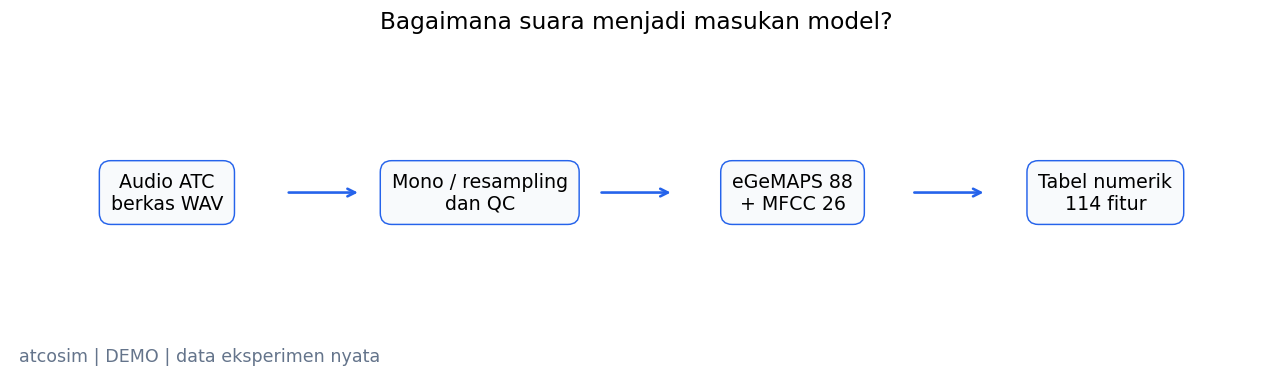

**Yang terlihat:** Alur berakhir pada 114 fitur akustik per ujaran, tanpa kelas fatigue.

**Artinya:** Representasi numerik memungkinkan pengujian model ketika label yang tepat tersedia.

**Perlu diingat:** Diagram menjelaskan proses; tidak menggambarkan model fatigue yang sudah dilatih.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [4]:
fig = flow(['Audio ATC\nberkas WAV', 'Mono / resampling\ndan QC', 'eGeMAPS 88\n+ MFCC 26', 'Tabel numerik\n114 fitur'],
           COLORS['audio'], 'Bagaimana suara menjadi masukan model?')
audio_book.show(fig, 'audio_ke_fitur',
                'Alur berakhir pada 114 fitur akustik per ujaran, tanpa kelas fatigue.',
                'Representasi numerik memungkinkan pengujian model ketika label yang tepat tersedia.',
                'Diagram menjelaskan proses; tidak menggambarkan model fatigue yang sudah dilatih.')

## 3. Data mentah dan preprocessing nyata

**Mono** merangkum kanal menjadi satu sinyal. **Resampling** mengubah jumlah sampel per detik agar sesuai extractor; tidak menambahkan informasi baru. Tidak ada denoising tersembunyi atau normalisasi amplitudo yang mengubah statistik suara. Untuk sampel yang sudah mono 16 kHz, perubahan format memang minimal.

In [5]:
import soundfile as sf
from atc_fatigue.audio.features import extract_file, feature_names, resample
sample_audio = audio_manifest.iloc[0]
raw_signal, source_rate = sf.read(sample_audio.original_path, always_2d=True)
mono_signal = raw_signal.mean(axis=1)
prepared_signal = resample(mono_signal, source_rate, config['audio']['sample_rate'])
display(pd.DataFrame([
    {'Tahap': 'Sebelum', 'Kanal': raw_signal.shape[1], 'Sample rate (Hz)': source_rate,
     'Durasi (s)': len(raw_signal)/source_rate, 'RMS (amplitudo relatif)': np.sqrt(np.mean(raw_signal**2))},
    {'Tahap': 'Sesudah', 'Kanal': 1, 'Sample rate (Hz)': config['audio']['sample_rate'],
     'Durasi (s)': len(prepared_signal)/config['audio']['sample_rate'],
     'RMS (amplitudo relatif)': np.sqrt(np.mean(prepared_signal**2))},
]))
live_audio_features = extract_file(sample_audio.original_path, config['audio'])
audio_columns = feature_names(config['audio']['n_mfcc'])
assert len(audio_columns) == 114 and len([c for c in audio_columns if c.startswith('egemaps__')]) == 88
display(pd.Series(live_audio_features)[audio_columns[:4] + ['mfcc_00_mean', 'mfcc_00_std']].to_frame('Nilai contoh asli — FRESH'))

,Tahap,Kanal,Sample rate (Hz),Durasi (s),RMS (amplitudo relatif)
0,Sebelum,1,16000,3.299812,0.039489
1,Sesudah,1,16000,3.299812,0.039489


,Nilai contoh asli — FRESH
egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,34.928963
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.25542
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0,26.382868
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,31.587996
mfcc_00_mean,-300.372742
mfcc_00_std,136.381836


### 3.1 Perjalanan satu rekaman ATC asli — pengaturan presentasi lokal

**Pertanyaan:** seperti apa suara yang benar-benar dipakai eksperimen sebelum menjadi 114 angka? **Waveform** adalah amplitudo sinyal terhadap waktu: pola dan level relatif terlihat, tetapi isi frekuensinya belum terpisah. Amplitudo besar tidak otomatis berarti fatigue atau volume absolut yang dapat dibandingkan antarperangkat.

File contoh sudah dibaca langsung di atas. Sel berikut menginspeksi dtype decoding, format berkas, kanal, sample rate, dan kualitasnya. **Stereo-to-mono hanya dilakukan bila rekaman memiliki beberapa kanal**; contoh mono tidak dibuat seolah mengalami perubahan stereo. Resampling menyamakan format, tanpa denoising atau penambahan informasi baru.

Grafik suara asli memerlukan opt-in **lokal**: `--private-media` pada runner, atau `ATC_NOTEBOOK_PRIVATE_MEDIA=1` sebelum membuka kernel interaktif. Ini untuk demonstrasi riset lokal sesuai audit penggunaan ATCOSIM; bukan izin redistribusi grafik/rekaman. **Runner selalu menghilangkan output sel bertag `private-media` pada salinan publik**, sambil menyimpan eksekusi asli di `runs/executions/`. Ilustrasi sintetis yang sudah ada tetap dipertahankan untuk pembaca GitHub.

In [6]:
from atc_fatigue.research.data import temporal_audio_representations, private_media_enabled
PRIVATE_AUDIO = private_media_enabled()
audio_header = sf.info(sample_audio.original_path)
actual_audio = temporal_audio_representations(raw_signal, source_rate, config['audio'])
actual_mfcc = actual_audio['mfcc']
np.testing.assert_allclose(actual_mfcc.mean(axis=1), [live_audio_features[f'mfcc_{i:02d}_mean'] for i in range(13)], rtol=1e-5, atol=1e-5)
np.testing.assert_allclose(actual_mfcc.std(axis=1), [live_audio_features[f'mfcc_{i:02d}_std'] for i in range(13)], rtol=1e-5, atol=1e-5)
display(pd.DataFrame([{'Sumber':'ATCOSIM asli; contoh yang sama dengan ekstraksi',
    'Sample rate sumber (Hz)':source_rate, 'Kanal':raw_signal.shape[1],
    'Durasi (detik)':len(raw_signal)/source_rate,'Dtype decoding':str(raw_signal.dtype),
    'Subtype berkas':audio_header.subtype,'Quality':live_audio_features['quality'],
    'Grafik asli lokal aktif':PRIVATE_AUDIO}]))
print('FRESH: representasi temporal dihitung dari berkas lokal; tidak dibaca dari feature cache.')

,Sumber,Sample rate sumber (Hz),Kanal,Durasi (detik),Dtype decoding,Subtype berkas,Quality,Grafik asli lokal aktif
0,ATCOSIM asli; contoh yang sama dengan ekstraksi,16000,1,3.299812,float64,PCM_16,ok,False


FRESH: representasi temporal dihitung dari berkas lokal; tidak dibaca dari feature cache.


In [7]:
if PRIVATE_AUDIO:
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
    axes[0].plot(np.arange(len(raw_signal))/source_rate, raw_signal[:,0], color=COLORS['secondary'], lw=0.7)
    axes[0].set(title=f'Raw waveform: kanal 1 / {raw_signal.shape[1]} kanal, {source_rate} Hz', ylabel='Amplitudo relatif')
    axes[1].plot(np.arange(len(actual_audio['prepared_signal']))/actual_audio['sample_rate'], actual_audio['prepared_signal'], color=COLORS['audio'], lw=0.7)
    axes[1].set(title=f"Sesudah: mono / {actual_audio['sample_rate']} Hz", xlabel='Waktu relatif ujaran (detik)', ylabel='Amplitudo relatif')
    fig.suptitle('ATCOSIM ASLI — raw dan processed waveform dari satu rekaman')
    audio_book.show(fig,'waveform_asli_lokal',f"Durasi sumber {len(raw_signal)/source_rate:.3f} detik; kanal sumber {raw_signal.shape[1]}.",
        'Perbandingan memperlihatkan perubahan format yang benar-benar diperlukan; input mono 16 kHz memang hampir tidak berubah.',
        'Satu contoh tidak mewakili seluruh speaker; grafik sumber ini hanya untuk presentasi lokal.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('Waveform asli dinonaktifkan untuk output publik; ilustrasi sintetis tetap tersedia di bawah.')

Visualisasi audio asli hanya tersedia pada salinan eksekusi lokal; output media dihilangkan dari salinan publik.


### 3.2 Waveform → frekuensi → Mel → MFCC

**Spectrogram** memecah sinyal menjadi jendela pendek, lalu menunjukkan kuatnya komponen frekuensi sepanjang waktu. **STFT** (*Short-Time Fourier Transform*) adalah transformasi yang dipakai: di sini 2.048 sampel per jendela dan hop 512 sampel, sama dengan parameter MFCC baseline librosa. Sumbu Hz menyatakan frekuensi; dB adalah level relatif terhadap maksimum contoh, bukan ukuran tekanan suara terkalibrasi.

**Mel spectrogram** mengelompokkan energi ke 128 pita frekuensi dengan resolusi menyerupai persepsi pendengaran. **MFCC** merangkum bentuk spektrum Mel menjadi koefisien; koefisien bukan pita Hz dan bukan label emosi/fatigue. Seluruh representasi berikut berasal dari **file yang sama**, dengan sample rate dan parameter extractor yang konsisten.

In [8]:
if PRIVATE_AUDIO:
    import librosa.display
    fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
    image = librosa.display.specshow(actual_audio['stft_db'], sr=actual_audio['sample_rate'], hop_length=actual_audio['hop_length'], x_axis='time', y_axis='linear', ax=ax, cmap='magma')
    ax.set(xlabel='Waktu relatif ujaran (detik)',ylabel='Frekuensi (Hz)',title='ATCOSIM ASLI — STFT magnitude setelah preprocessing')
    fig.colorbar(image,ax=ax,label='Magnitude relatif maksimum (dB)')
    audio_book.show(fig,'stft_asli_lokal',f"STFT menghasilkan {actual_audio['stft_db'].shape[0]} bin frekuensi × {actual_audio['stft_db'].shape[1]} frame waktu.",
        'Sumbu frekuensi memisahkan energi yang bercampur pada waveform; warna bukan tingkat fatigue.',
        'Skala dB relatif per contoh; tidak membandingkan loudness absolut antaroperator.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('STFT rekaman asli tersedia hanya dengan opt-in presentasi lokal.')

Visualisasi audio asli hanya tersedia pada salinan eksekusi lokal; output media dihilangkan dari salinan publik.


In [9]:
if PRIVATE_AUDIO:
    fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
    image = librosa.display.specshow(actual_audio['log_mel_db'],sr=actual_audio['sample_rate'],hop_length=actual_audio['hop_length'],x_axis='time',y_axis='mel',ax=ax,cmap='magma')
    ax.set(xlabel='Waktu relatif ujaran (detik)',ylabel='Frekuensi (Hz; skala Mel)',title='ATCOSIM ASLI — 128 pita Mel dari rekaman yang sama')
    fig.colorbar(image,ax=ax,label='Daya relatif maksimum (dB)')
    audio_book.show(fig,'logmel_asli_lokal',f"Log-Mel memiliki {actual_audio['log_mel_db'].shape[0]} pita dan {actual_audio['log_mel_db'].shape[1]} frame waktu.",
        'Pemetaan Mel menekankan struktur spektrum yang menjadi bahan perhitungan MFCC.',
        'Warna bersifat relatif; representasi turunan tetap dapat mengungkap sumber dan tidak dipublikasikan.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('Log-Mel rekaman asli tersedia hanya pada salinan lokal.')

Visualisasi audio asli hanya tersedia pada salinan eksekusi lokal; output media dihilangkan dari salinan publik.


In [10]:
if PRIVATE_AUDIO:
    fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
    image = ax.imshow(actual_mfcc,origin='lower',aspect='auto',cmap='coolwarm',extent=[0,len(actual_audio['prepared_signal'])/actual_audio['sample_rate'],-0.5,12.5])
    ax.set(xlabel='Waktu relatif ujaran (detik)',ylabel='Indeks koefisien MFCC',title='ATCOSIM ASLI — 13 MFCC sebelum diringkas per utterance')
    fig.colorbar(image,ax=ax,label='Nilai koefisien (skala komputasi librosa)')
    audio_book.show(fig,'mfcc_asli_lokal',f"Terdapat 13 koefisien pada {actual_mfcc.shape[1]} frame waktu; rerata/std cocok dengan extractor baseline.",
        'Setiap baris merangkum aspek bentuk spektrum; ringkasan mengubah panjang rekaman berbeda menjadi vektor tetap.',
        'Mean/std membuang urutan perubahan; distribusi koefisien bukan bukti kondisi fatigue.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('Heatmap MFCC rekaman asli tidak disimpan pada notebook publik.')

Visualisasi audio asli hanya tersedia pada salinan eksekusi lokal; output media dihilangkan dari salinan publik.


### 3.3 Mengapa akhirnya ada 114 fitur?

Konfigurasi **eGeMAPSv02 Functionals** secara definisi mengeluarkan 88 ringkasan akustik; angka ini berasal dari spesifikasi feature set, bukan hasil pemilihan jumlah fitur berdasarkan skor. MFCC di baseline memakai 13 koefisien, masing-masing diringkas dengan mean (rerata) dan std (simpangan baku): **13 × 2 = 26**. Keduanya menghasilkan **88 + 26 = 114** kolom numerik per utterance.

Contoh: mean MFCC menggambarkan bentuk spektrum rata-rata, sementara std menggambarkan variasinya selama ujaran. Fitur pitch merangkum pola nada dengan unit yang perlu dibaca per kolom. Ringkasan ini tidak mempertahankan semua urutan waktu, dapat berubah karena mikrofon/bahasa/noise, dan tidak spesifik fatigue. Tanpa label fatigue independen, ekstraksi yang berhasil belum berarti model mendeteksi kelelahan.

In [11]:
display(pd.DataFrame([
    {'Representasi':'Sinyal setelah preprocessing','Baris temporal':len(actual_audio['prepared_signal']),'Ringkasan model':'Tidak langsung dipakai sebagai vektor tabular'},
    {'Representasi':'MFCC temporal','Baris temporal':actual_mfcc.shape[1],'Ringkasan model':'13 mean + 13 std = 26 fitur'},
    {'Representasi':'eGeMAPSv02 Functionals','Baris temporal':1,'Ringkasan model':'88 ringkasan dengan unit berbeda'},
    {'Representasi':'Tabel per utterance','Baris temporal':1,'Ringkasan model':'114 kolom; tidak ada fatigue label'},
]))
display(pd.DataFrame({'MFCC mean temporal':actual_mfcc.mean(axis=1)[:3],
                      'MFCC mean extractor':[live_audio_features[f'mfcc_{i:02d}_mean'] for i in range(3)]},index=['Koefisien 0','Koefisien 1','Koefisien 2']))

,Representasi,Baris temporal,Ringkasan model
0,Sinyal setelah preprocessing,52797,Tidak langsung dipakai sebagai vektor tabular
1,MFCC temporal,104,13 mean + 13 std = 26 fitur
2,eGeMAPSv02 Functionals,1,88 ringkasan dengan unit berbeda
3,Tabel per utterance,1,114 kolom; tidak ada fatigue label


,MFCC mean temporal,MFCC mean extractor
Koefisien 0,-300.372742,-300.372742
Koefisien 1,12.776952,12.776952
Koefisien 2,-32.792816,-32.792816


### Membaca bentuk sinyal tanpa membagikan suara peserta

Ilustrasi deterministik berikut terdiri dari tiga gelombang harmonik dan perubahan amplitudo; ini **bukan suara ATC**. Sumbu waktu tetap detik. Contoh memperlihatkan perubahan representasi stereo 32 kHz menjadi mono 16 kHz; tabel sebelumnya menunjukkan preprocessing pada file asli.

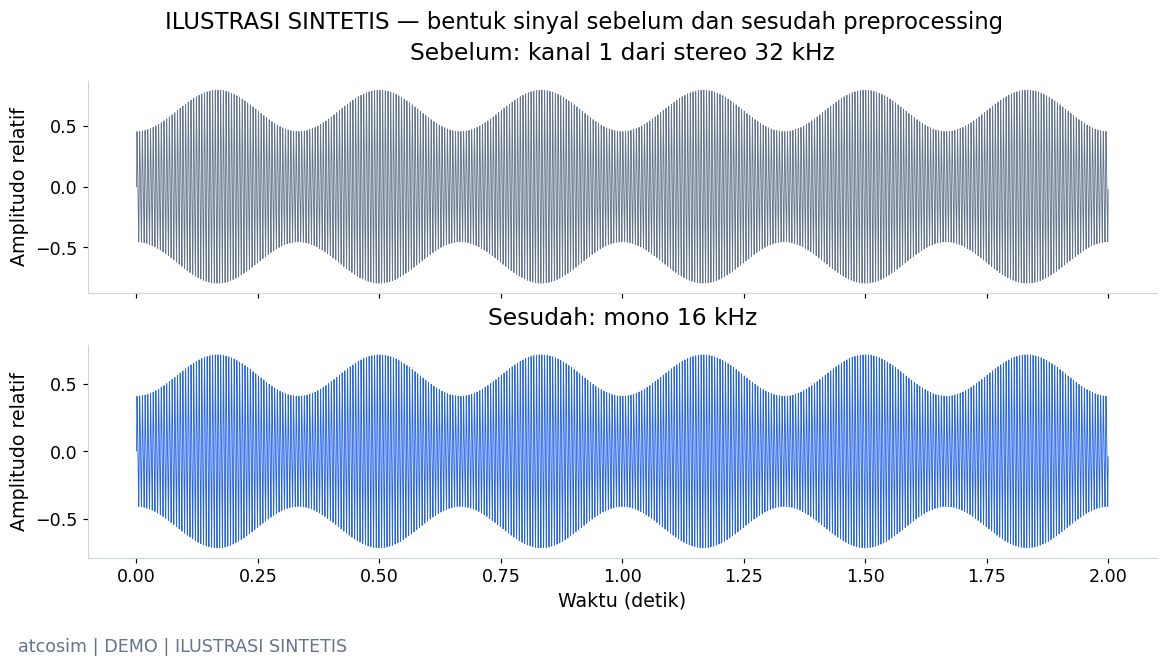

**Yang terlihat:** Sinyal dua detik mempertahankan durasi setelah jumlah sampel per detik diubah.

**Artinya:** Resampling menyamakan format masukan extractor, bukan membuat label.

**Perlu diingat:** Sinyal ini buatan dan tidak masuk eksperimen atau skor.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [12]:
illustration_rate = 32000
illustration_time = np.arange(illustration_rate * 2) / illustration_rate
envelope = 0.4 + 0.3 * np.sin(2*np.pi*1.5*illustration_time)**2
synthetic_mono = envelope * (np.sin(2*np.pi*180*illustration_time) + 0.3*np.sin(2*np.pi*360*illustration_time))
synthetic_stereo = np.column_stack([synthetic_mono, synthetic_mono*0.8])
synthetic_prepared = resample(synthetic_stereo.mean(axis=1), illustration_rate, 16000)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.8), layout='constrained', sharex=True)
axes[0].plot(illustration_time, synthetic_stereo[:, 0], color=COLORS['secondary'], lw=0.6)
axes[1].plot(np.arange(len(synthetic_prepared))/16000, synthetic_prepared, color=COLORS['audio'], lw=0.6)
for ax, label in zip(axes, ['Sebelum: kanal 1 dari stereo 32 kHz', 'Sesudah: mono 16 kHz']):
    ax.set(ylabel='Amplitudo relatif', title=label)
axes[1].set_xlabel('Waktu (detik)')
fig.suptitle('ILUSTRASI SINTETIS — bentuk sinyal sebelum dan sesudah preprocessing')
audio_book.show(fig, 'waveform_sintetis',
                'Sinyal dua detik mempertahankan durasi setelah jumlah sampel per detik diubah.',
                'Resampling menyamakan format masukan extractor, bukan membuat label.',
                'Sinyal ini buatan dan tidak masuk eksperimen atau skor.', synthetic=True)

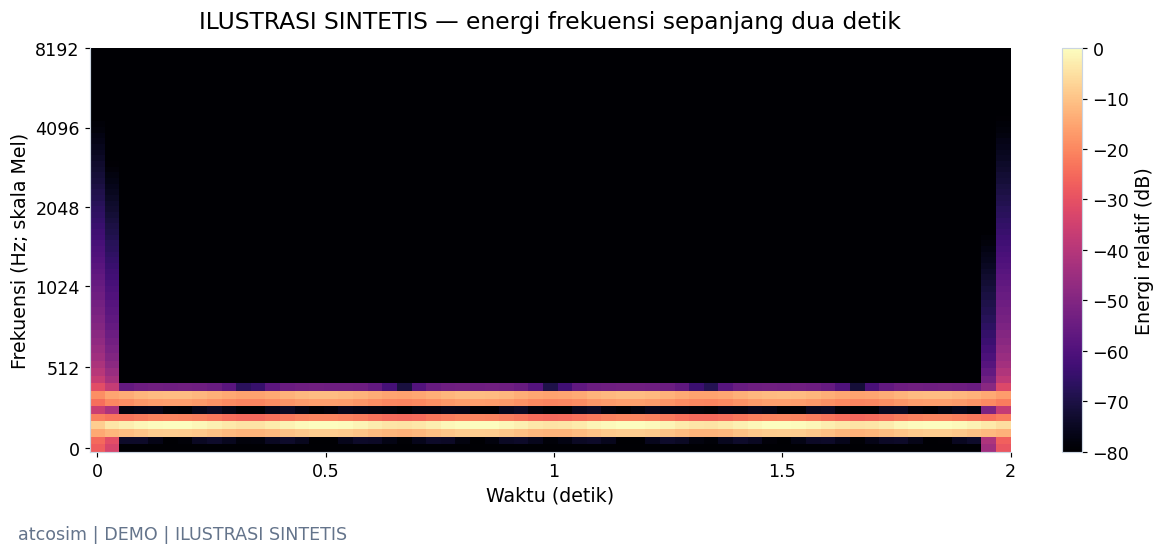

**Yang terlihat:** Energi terkonsentrasi di frekuensi harmonik yang dipakai membentuk sinyal buatan.

**Artinya:** Spektrogram memisahkan informasi waktu dan frekuensi yang tidak terlihat pada satu angka RMS.

**Perlu diingat:** Mel menekankan resolusi frekuensi menurut persepsi pendengaran; bukan indikator fatigue.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [13]:
import librosa
import librosa.display
mel_power = librosa.feature.melspectrogram(y=synthetic_prepared, sr=16000, n_mels=64)
log_mel = librosa.power_to_db(mel_power, ref=np.max)
fig, ax = plt.subplots(layout='constrained')
image = librosa.display.specshow(log_mel, sr=16000, x_axis='time', y_axis='mel', ax=ax, cmap='magma')
ax.set(xlabel='Waktu (detik)', ylabel='Frekuensi (Hz; skala Mel)',
       title='ILUSTRASI SINTETIS — energi frekuensi sepanjang dua detik')
fig.colorbar(image, ax=ax, label='Energi relatif (dB)')
audio_book.show(fig, 'logmel_sintetis',
                'Energi terkonsentrasi di frekuensi harmonik yang dipakai membentuk sinyal buatan.',
                'Spektrogram memisahkan informasi waktu dan frekuensi yang tidak terlihat pada satu angka RMS.',
                'Mel menekankan resolusi frekuensi menurut persepsi pendengaran; bukan indikator fatigue.', synthetic=True)

## 4. Feature engineering: dari spektrum ke tabel

**eGeMAPS** adalah paket 88 ringkasan fitur akustik, termasuk nada, energi, spektrum, dan kualitas suara. **MFCC** (*Mel-frequency cepstral coefficients*) merangkum bentuk spektrum; 13 koefisien dihitung sepanjang waktu, lalu masing-masing diringkas dengan rerata dan simpangan baku: **13 × 2 = 26**.

Satu nilai fitur belum memiliki arti klinis. Unit antarfitur berbeda: pitch semitone bukan Hz, loudness bukan RMS, dan nilai MFCC bersifat koefisien. Tabel contoh asli di atas sengaja hanya menampilkan beberapa kolom.

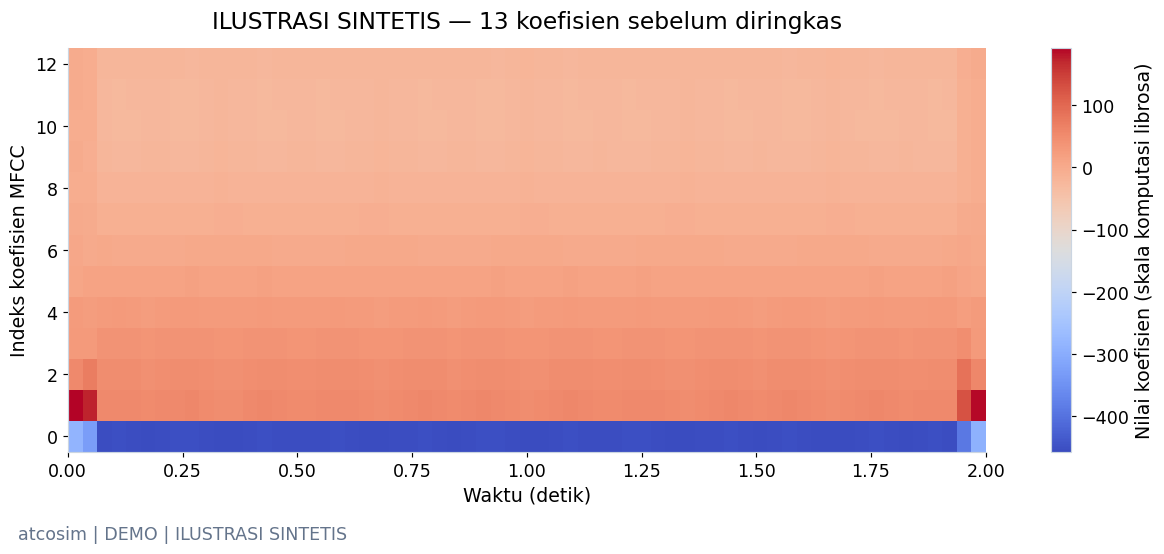

**Yang terlihat:** Setiap baris mengikuti satu koefisien; tabel model merangkum rerata dan variasinya.

**Artinya:** Ringkasan mengubah sinyal berdurasi berbeda menjadi vektor dengan panjang tetap.

**Perlu diingat:** Matriks ini sintetis; 114 fitur eksperimen dihitung dari audio ATCOSIM asli.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [14]:
synthetic_mfcc = librosa.feature.mfcc(y=synthetic_prepared, sr=16000, n_mfcc=13)
fig, ax = plt.subplots(layout='constrained')
image = ax.imshow(synthetic_mfcc, aspect='auto', origin='lower', cmap='coolwarm',
                  extent=[0, 2, -0.5, 12.5])
ax.set(xlabel='Waktu (detik)', ylabel='Indeks koefisien MFCC',
       title='ILUSTRASI SINTETIS — 13 koefisien sebelum diringkas')
fig.colorbar(image, ax=ax, label='Nilai koefisien (skala komputasi librosa)')
audio_book.show(fig, 'mfcc_sintetis',
                'Setiap baris mengikuti satu koefisien; tabel model merangkum rerata dan variasinya.',
                'Ringkasan mengubah sinyal berdurasi berbeda menjadi vektor dengan panjang tetap.',
                'Matriks ini sintetis; 114 fitur eksperimen dihitung dari audio ATCOSIM asli.', synthetic=True)

## 5. Ekstraksi seluruh subset dan quality control

Pada **FULL**, loop berikut benar-benar membaca semua file dan mengekstrak fiturnya. Pada **DEMO**, tabel seluruh subset diambil dari run tersimpan yang telah diverifikasi, sedangkan contoh asli tetap dihitung langsung. Sampel hening/terlalu pendek menghasilkan flag dan nilai hilang, bukan fitur suara nol yang dianggap valid.

In [15]:
if RUN_MODE == 'FULL':
    extraction_started = time.perf_counter()
    audio_rows = []
    for row in audio_manifest.to_dict('records'):
        audio_rows.append({**row, **extract_file(row['original_path'], config['audio'])})
    audio_features = pd.DataFrame(audio_rows)
    audio_run.features(audio_features, audio_columns, 'audio-egemapsv02-mfcc13-v1')
    audio_run.log('extract_all_audio', {'rows': len(audio_features), 'seconds': time.perf_counter()-extraction_started})
else:
    audio_features = pd.read_parquet(audio_run.path / 'features/features.parquet')
np.testing.assert_allclose(audio_features.loc[audio_features.sample_id.eq(sample_audio.sample_id), audio_columns].iloc[0].to_numpy(float),
                           np.array([live_audio_features[c] for c in audio_columns]), equal_nan=True, rtol=1e-5)
audio_qc = {'rows': len(audio_features), 'subjects': int(audio_features.subject_id.nunique()),
            'sessions': int(audio_features.session_id.nunique()),
            'duration_seconds': float(audio_features.duration_seconds.sum()),
            'feature_missing_fraction': float(audio_features[audio_columns].isna().mean().mean()),
            'quality_counts': audio_features.quality.value_counts().to_dict(),
            'evaluation_rows': len(audio_features)}
display(audio_features[['duration_seconds', 'source_sample_rate', 'source_channels', 'quality']].head())
display(pd.DataFrame([audio_qc]).drop(columns='quality_counts'))

,duration_seconds,source_sample_rate,source_channels,quality
0,3.299812,16000,1,ok
1,4.660000,16000,1,ok
2,4.229813,16000,1,ok
3,2.640000,16000,1,ok
4,3.910000,16000,1,ok


,rows,subjects,sessions,duration_seconds,feature_missing_fraction,evaluation_rows
0,100,1,1,425.614688,0.0,100


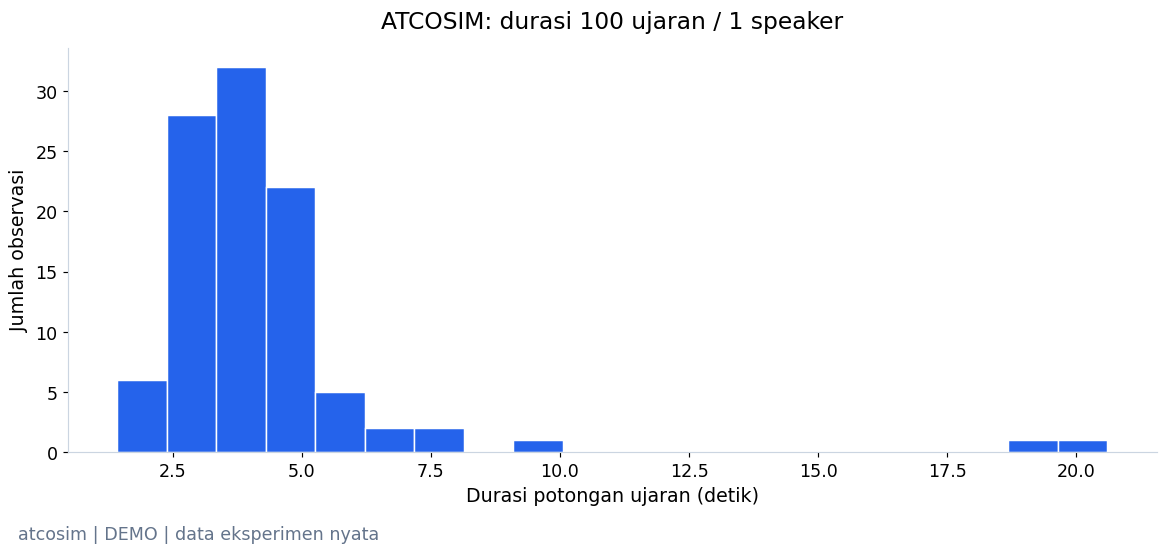

**Yang terlihat:** Total audio 425.61 detik; median ujaran 3.92 detik.

**Artinya:** Durasi bervariasi, sehingga ringkasan fitur berdimensi tetap membantu menyusun tabel.

**Perlu diingat:** Ini durasi potongan rekaman, bukan waktu speech bersih hasil VAD atau sesi kontinu.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [16]:
fig = histogram(audio_features.duration_seconds, 'Durasi potongan ujaran (detik)',
                f'ATCOSIM: durasi {len(audio_features)} ujaran / {audio_features.subject_id.nunique()} speaker', COLORS['audio'])
audio_book.show(fig, 'distribusi_durasi',
                f'Total audio {audio_qc["duration_seconds"]:.2f} detik; median ujaran {audio_features.duration_seconds.median():.2f} detik.',
                'Durasi bervariasi, sehingga ringkasan fitur berdimensi tetap membantu menyusun tabel.',
                'Ini durasi potongan rekaman, bukan waktu speech bersih hasil VAD atau sesi kontinu.')

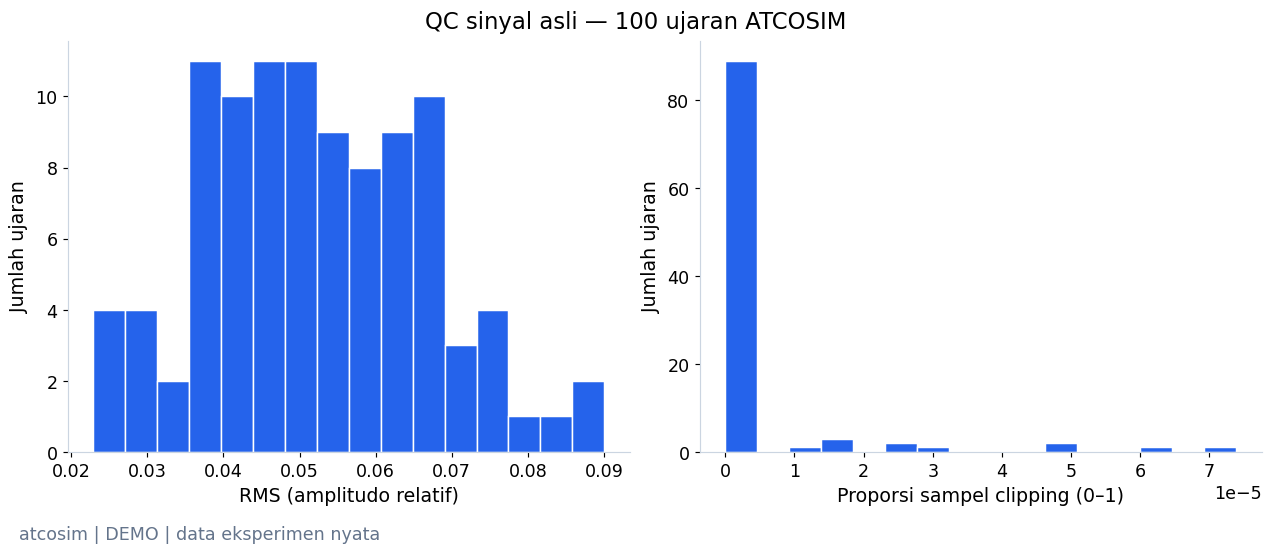

**Yang terlihat:** RMS median 0.051524; clipping maksimum 0.000074.

**Artinya:** Pemeriksaan ini mendeteksi persoalan level sinyal sebelum fitur dipakai model.

**Perlu diingat:** RMS dan clipping bukan estimasi SNR, VAD, atau kondisi fatigue.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for ax, column, label in zip(axes, ['rms', 'clipping_fraction'], ['RMS (amplitudo relatif)', 'Proporsi sampel clipping (0–1)']):
    ax.hist(audio_features[column], bins=16, color=COLORS['audio'], edgecolor='white')
    ax.set(xlabel=label, ylabel='Jumlah ujaran')
    ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 3))
fig.suptitle(f'QC sinyal asli — {len(audio_features)} ujaran ATCOSIM')
audio_book.show(fig, 'rms_dan_clipping',
                f'RMS median {audio_features.rms.median():.6f}; clipping maksimum {audio_features.clipping_fraction.max():.6f}.',
                'Pemeriksaan ini mendeteksi persoalan level sinyal sebelum fitur dipakai model.',
                'RMS dan clipping bukan estimasi SNR, VAD, atau kondisi fatigue.')

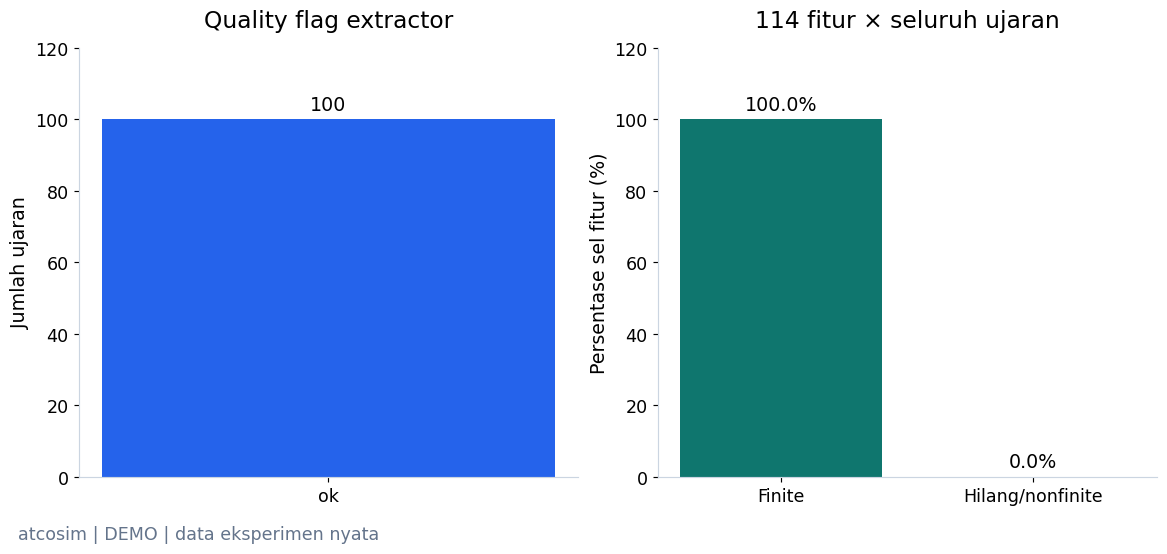

**Yang terlihat:** 100 ujaran tersedia; 100.0% sel fitur finite.

**Artinya:** Pipeline dapat membentuk tabel tanpa mengarang pengukuran pada sampel tidak valid.

**Perlu diingat:** Quality ok adalah kelayakan teknis ekstraksi, bukan validasi biomarker atau generalisasi.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
counts = audio_features.quality.value_counts()
bars = axes[0].bar(counts.index, counts.values, color=COLORS['audio'])
axes[0].bar_label(bars, padding=4)
axes[0].set(ylabel='Jumlah ujaran', title='Quality flag extractor', ylim=(0, counts.max()*1.2))
finite_percent = 100 * np.isfinite(audio_features[audio_columns].to_numpy(float)).mean()
bars = axes[1].bar(['Finite', 'Hilang/nonfinite'], [finite_percent, 100-finite_percent],
                   color=[COLORS['fusion'], COLORS['error']])
axes[1].bar_label(bars, fmt='%.1f%%', padding=4)
axes[1].set(ylabel='Persentase sel fitur (%)', title='114 fitur × seluruh ujaran', ylim=(0, 120))
audio_book.show(fig, 'kualitas_dan_missingness',
                f'{int(audio_features.audio_available.sum())} ujaran tersedia; {finite_percent:.1f}% sel fitur finite.',
                'Pipeline dapat membentuk tabel tanpa mengarang pengukuran pada sampel tidak valid.',
                'Quality ok adalah kelayakan teknis ekstraksi, bukan validasi biomarker atau generalisasi.')

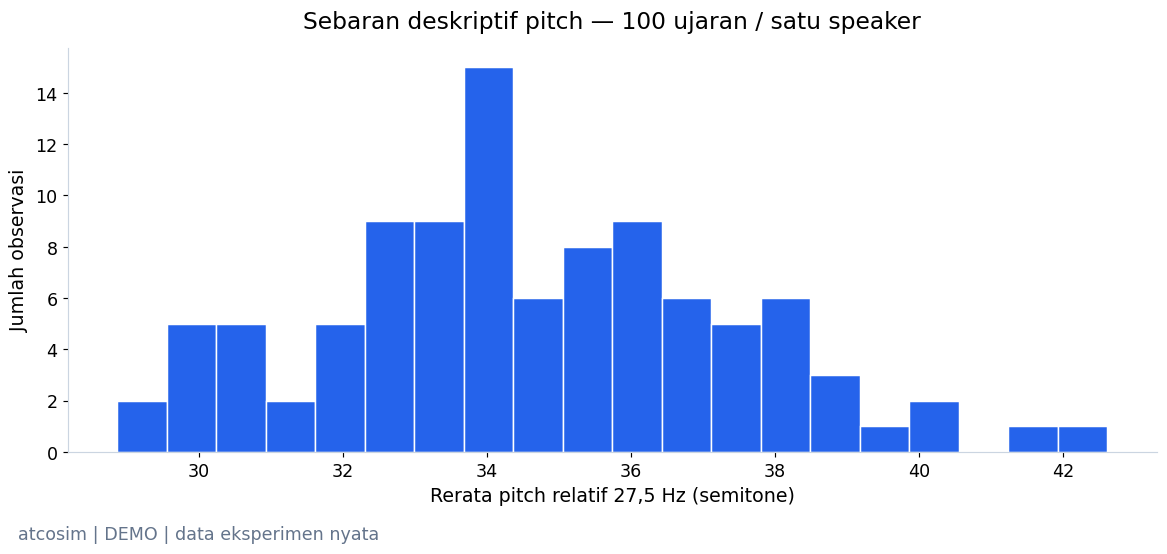

**Yang terlihat:** Median fitur pitch pada subset 34.30 semitone.

**Artinya:** Satu fitur memiliki variasi antarujaran meskipun berasal dari speaker yang sama.

**Perlu diingat:** Tidak ada kelompok fatigue/non-fatigue untuk menguji apakah variasi ini berkaitan dengan kelelahan.

*Sumber: `20261022T133504291481Z_seed42_84e529` · CACHED + contoh diproses langsung.*

In [19]:
pitch_column = next(c for c in audio_columns if 'F0semitoneFrom27.5Hz_sma3nz_amean' in c)
fig = histogram(audio_features[pitch_column].to_numpy(float), 'Rerata pitch relatif 27,5 Hz (semitone)',
                f'Sebaran deskriptif pitch — {len(audio_features)} ujaran / satu speaker', COLORS['audio'])
audio_book.show(fig, 'distribusi_pitch',
                f'Median fitur pitch pada subset {audio_features[pitch_column].median():.2f} semitone.',
                'Satu fitur memiliki variasi antarujaran meskipun berasal dari speaker yang sama.',
                'Tidak ada kelompok fatigue/non-fatigue untuk menguji apakah variasi ini berkaitan dengan kelelahan.')

## 6. Temuan, keterbatasan, dan langkah berikutnya

Pipeline menghasilkan representasi akustik dan QC yang dapat diperiksa. Subset first-100 dari satu speaker/sesi belum menguji variasi aksen, operator, mikrofon, atau radio terkompresi. Tidak ada timeline pilot yang sah untuk menghitung latency respons, dan tidak ada label fatigue untuk melatih classifier.

Kandidat berikutnya adalah IEEE ATC Radiotelephony Fatigue Corpus, DOI `10.21227/70sz-mj23`. **Menurut pembaruan pengguna pada spesifikasi v3, permintaan akses sudah dikirim; akses/data belum tersedia.** Notebook tidak mencoba mengunduh atau melewati login. Setelah akses sah, label, speaker, channel, duplikasi dan split perlu diaudit terlebih dahulu.

## 7. Provenance dan reproduksi

FULL menyimpan manifest sumber, konfigurasi, versi environment, schema, Parquet, QC, log dan grafik. File model/prediksi tidak berlaku karena tidak ada label. Grafik ilustrasi sintetis tidak digunakan sebagai data eksperimen.

In [20]:
audio_book.finish()
if RUN_MODE == 'FULL':
    audio_metrics = metrics_base(audio_run, {}, {}, {}, baseline=None)
    audio_run.complete(audio_metrics, audio_qc, warning_records)
display(pd.DataFrame([{'Run ID': audio_run.manifest['run_id'], 'Mode': RUN_MODE,
                       'Ujaran': len(audio_features), 'Fitur': len(audio_columns),
                       'Metrik supervised': 'N/A — no_fatigue_labels',
                       'Artifact': str(audio_run.path.relative_to(ROOT))}]))

,Run ID,Mode,Ujaran,Fitur,Metrik supervised,Artifact
0,20261022T133504291481Z_seed42_84e529,DEMO,100,114,N/A — no_fatigue_labels,runs/atcosim_audio/20261022T133504291481Z_seed...


## 7. Audit kandidat fatigue: apa sebenarnya label Predi-COVID?

**Pertanyaan:** apakah kita dapat melatih model suara dengan target fatigue yang benar-benar tercatat?
ATCOSIM tidak menyediakan label tersebut. Predi-COVID menyediakan rekaman peserta dengan COVID-19 terkonfirmasi,
beserta laporan keadaan hari itu. Ini membuka supervised benchmark **fatigue klinis**, dengan domain gap besar terhadap ATC.

Menurut [paper peneliti](https://bmjopen.bmj.com/content/12/11/e062463), jawaban *I feel well* menjadi kelas 0;
*I am fatigued* **dan** *I don't feel well* menjadi kelas 1. Jadi kelas 1 mencampur kelelahan dengan rasa tidak sehat;
bukan diagnosis objektif, skala occupational fatigue, atau label yang dinilai per segmen suara.
[Zenodo 5937844](https://zenodo.org/records/5937844) menyediakan WAV dan metadata terbuka CC BY 4.0.
Kode penulis tidak disalin; notebook ini memakai extractor 114 fitur yang sama dengan ATCOSIM.

| Audit | Keputusan sebelum melihat performa |
| :--- | :--- |
| Arsip sumber | 3.544 WAV / 296 peserta; membaca teks (tipe 1) dan vokal (tipe 2), total sekitar 4,38 GiB |
| Subset berizin | Seed 42 memilih 120 peserta; maksimal dua rekaman membaca teks paling awal per peserta: 207 WAV, sekitar 338 MiB |
| Pemilihan | Tidak memakai skor model atau mencari kelas paling mudah; bukan sampel representatif populasi klinis |
| Identitas berulang | Semua rekaman/hari dari satu peserta tetap dalam satu split; hash duplikat diperiksa lintas split |
| Label | Binary publisher; keadaan klinis sehari, bukan fatigue ATC |
| Confound | Penyakit, demografi, perangkat/format asli, bahasa, tanggal dan protokol membaca |
| Bahasa | Sumber studi multibahasa; bahasa per rekaman tidak tersedia pada nama file, sehingga belum dapat dikontrol |
| Publikasi | Hanya ringkasan agregat; WAV, metadata peserta, model dan cache fitur tetap lokal |

**Input → output:** manifest lokal dengan checksum → QC audio → fitur 114 dimensi → split peserta → model tetap → prediksi holdout.
Tidak ada unduhan otomatis ketika Run All. Jika manifest belum tersedia, bagian ini menjelaskan kebutuhan akses dan tidak membuat skor pengganti.

In [21]:
PREDI_AVAILABLE = Path(config['additional_datasets']['predi_manifest']).exists()
if PREDI_AVAILABLE:
    predi_manifest = local_manifest(config['additional_datasets']['predi_manifest'], target='clinical_fatigue_binary')
    predi_rights = {'source':'https://zenodo.org/records/5937844', 'variant':'seed42;120 participants;task1;max2 earliest;207 recordings',
                    'rights':'CC BY 4.0; LIHVOICE; clinical data; aggregate-only public presentation'}
    predi_limits = ['clinical fatigue/unwell self-report is not occupational ATC fatigue',
                    'COVID illness, language, device and demographics may confound acoustic associations',
                    'repeated same-subject measurements; small fixed subject-independent subset',
                    'recording-level scores; clips within subjects are dependent; no clip-level confidence interval']
    if RUN_MODE == 'FULL':
        predi_run = Run.create('predi_covid_fatigue','01_audio_analysis.ipynb',config,predi_manifest,
                               'audio-egemapsv02-mfcc13-v1',predi_rights,predi_limits)
    else:
        predi_run,predi_metrics = cached_run('predi_covid_fatigue',config)
    predi_book = FigureBook(predi_run,RUN_MODE,config)
    run_card(predi_run,RUN_MODE,'Target: clinical_fatigue_binary; bukan fatigue ATC')
else:
    display(Markdown('**BLOCKED lokal:** manifest Predi-COVID belum tersedia. Persiapkan subset berizin; tidak ada training atau skor fiktif.'))

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; contoh ekstraksi/inference diproses langsung** |
| Run ID sumber | `20261022T133521652181Z_seed42_d98d66` |
| Status eksperimen sumber | completed |
| Dataset / target | predi_covid / clinical_fatigue_binary |
| Sampel / subjek | 207 / 120 |
| Unit evaluasi | recording; held-out participant |
| Hasil utama | Target: clinical_fatigue_binary; bukan fatigue ATC |

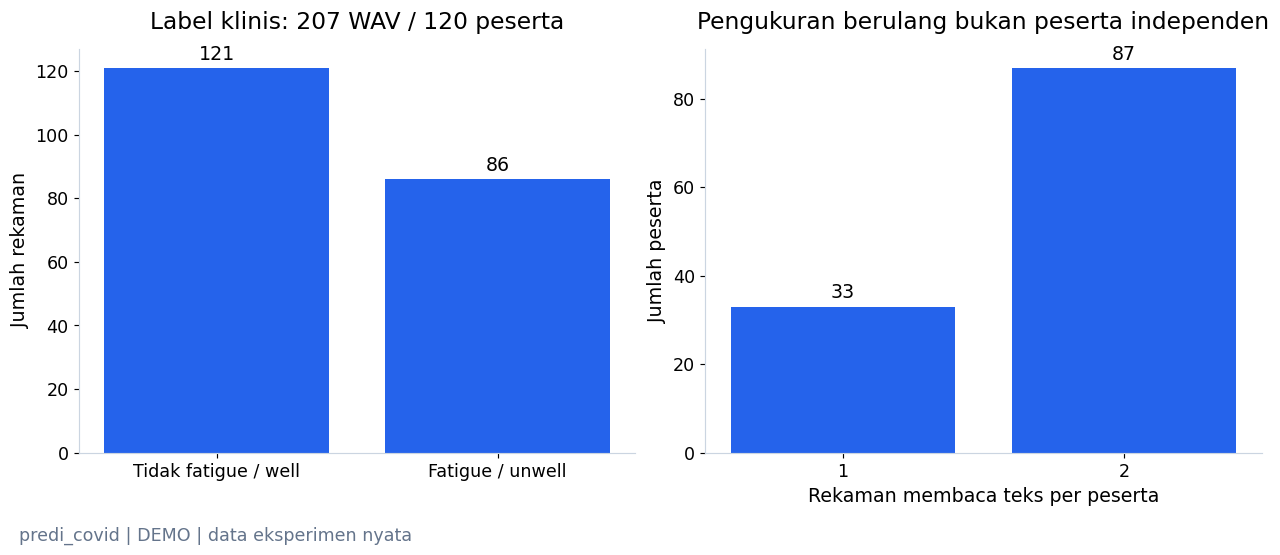

**Yang terlihat:** Kelas 0 berisi 121 rekaman, kelas 1 berisi 86; subset maksimal dua rekaman per peserta.

**Artinya:** Ketidakseimbangan kelas memerlukan baseline mayoritas, Macro F1, balanced accuracy dan recall tiap kelas.

**Perlu diingat:** Label unwell mencakup gejala selain fatigue; dua rekaman dari orang sama tidak setara dua orang.

*Sumber: `20261022T133521652181Z_seed42_d98d66` · FRESH — manifest sumber terverifikasi.*

Label klinis                 0   1
sex_metadata source_format        
M            3gp            29  16
             m4a            37  15
W            3gp            13  20
             m4a            42  35

In [22]:
if PREDI_AVAILABLE:
    fig, axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
    counts = predi_manifest.target_value.value_counts().reindex([0,1],fill_value=0)
    bars = axes[0].bar(['Tidak fatigue / well','Fatigue / unwell'],counts,color=COLORS['audio'])
    axes[0].bar_label(bars,padding=3)
    axes[0].set(ylabel='Jumlah rekaman',title=f'Label klinis: {len(predi_manifest)} WAV / {predi_manifest.subject_id.nunique()} peserta')
    repeats = predi_manifest.groupby('subject_id').size().value_counts().sort_index()
    bars = axes[1].bar(repeats.index.astype(str),repeats.values,color=COLORS['audio'])
    axes[1].bar_label(bars,padding=3)
    axes[1].set(xlabel='Rekaman membaca teks per peserta',ylabel='Jumlah peserta',title='Pengukuran berulang bukan peserta independen')
    predi_book.show(fig,'predi_label_dan_pengulangan',
                    f'Kelas 0 berisi {counts[0]} rekaman, kelas 1 berisi {counts[1]}; subset maksimal dua rekaman per peserta.',
                    'Ketidakseimbangan kelas memerlukan baseline mayoritas, Macro F1, balanced accuracy dan recall tiap kelas.',
                    'Label unwell mencakup gejala selain fatigue; dua rekaman dari orang sama tidak setara dua orang.',origin='FRESH — manifest sumber terverifikasi')
    display(predi_manifest.groupby(['sex_metadata','source_format','target_value']).size().unstack(fill_value=0).rename_axis(columns='Label klinis'))

### 7.1 QC dan split peserta sebelum training

**Mengapa tahap ini diperlukan?** File yang berhasil diunduh belum tentu memuat sinyal yang layak.
Checksum SHA-256 dan MD5 penerbit diverifikasi saat persiapan; extractor memeriksa durasi, RMS (kuat sinyal rata-rata),
clipping (amplitudo mencapai batas digital), sample rate, kanal, serta nilai fitur yang hilang.
Semua rekaman diperiksa. Tidak ada penghapusan berdasarkan skor model; jika fitur tidak valid, eksekusi berhenti untuk audit.

Split `GroupShuffleSplit` memakai seed 42: sekitar 20% peserta test, lalu 20% dari sisanya validation.
Batas subjek diperiksa sebelum fitting. Validation ditampilkan untuk transparansi dan **tidak** dipakai mencari parameter terbaik.
Format 3GP/M4A pada metadata adalah format perangkat **sebelum** konversi penerbit ke WAV; bukan format berkas yang kita decode sekarang.

,Rekaman,Peserta,Fatigue,Durasi_detik
split,,,,
test,42,24,18,1196.308955
train,129,76,46,3653.019825
validation,36,20,22,1015.339957


,Rekaman,RMS_min,Clipping_maks,Sample_rate_min
quality,,,,
ok,207,0.024156,0.0,8000


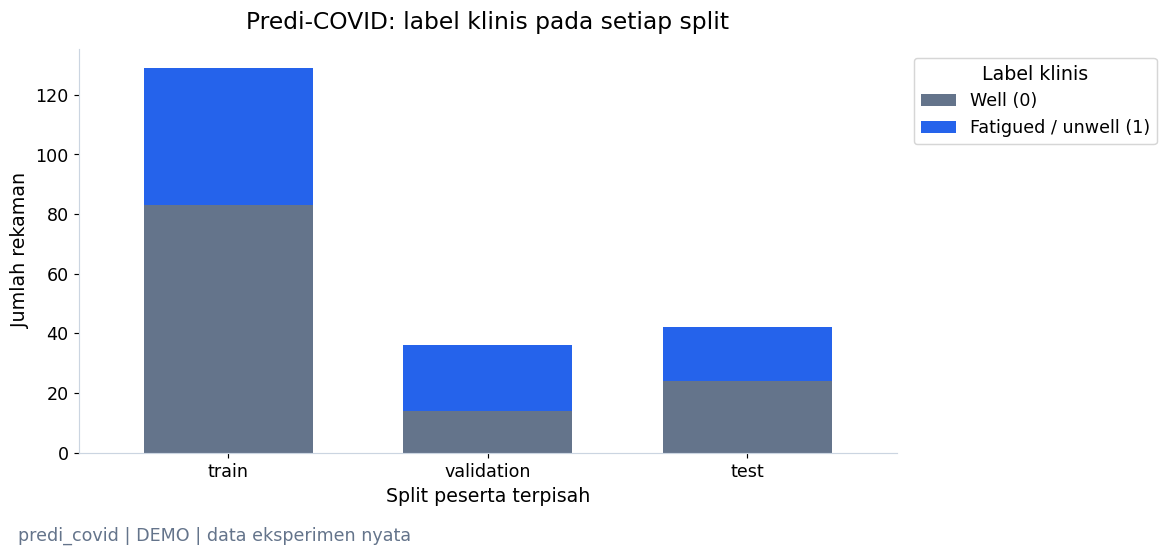

**Yang terlihat:** Seluruh hari dan rekaman seorang peserta berada pada satu bagian data; overlap subjek dan checksum lintas split = 0.

**Artinya:** Model diuji pada peserta yang tidak dipakai fitting, sehingga tidak cukup menghafal identitas suara training.

**Perlu diingat:** Split independen tidak menghapus confound klinis atau memastikan populasi test mewakili operator ATC.

*Sumber: `20261022T133521652181Z_seed42_d98d66` · CACHED + contoh diproses langsung.*

In [23]:
if PREDI_AVAILABLE:
    from atc_fatigue.models.baselines import subject_split, classification_metrics
    if RUN_MODE == 'FULL':
        predi_rows = [{**row,**extract_file(row['original_path'],config['audio'])}
                      for row in predi_manifest.to_dict('records')]
        predi_data = subject_split(pd.DataFrame(predi_rows),config['seed'])
        if not np.isfinite(predi_data[audio_columns].to_numpy(float)).all() or not predi_data.quality.eq('ok').all():
            raise ValueError('Predi-COVID QC requires explicit review; no silent removal or substitution')
        predi_run.features(predi_data,audio_columns,'audio-egemapsv02-mfcc13-v1')
        predi_data[['sample_id','subject_id','session_id','source_checksum','target_value','split']].to_csv(
            predi_run.file('split_manifest.csv'),index=False)
    else:
        predi_data = pd.read_parquet(predi_run.path/'features/features.parquet')
    assert predi_data.groupby('subject_id').split.nunique().max()==1
    assert predi_data.groupby('source_checksum').split.nunique().max()==1
    predi_sizes = predi_data.groupby('split').size().to_dict()
    display(predi_data.groupby('split').agg(Rekaman=('sample_id','size'),Peserta=('subject_id','nunique'),
                                           Fatigue=('target_value','sum'),Durasi_detik=('duration_seconds','sum')))
    display(predi_data.groupby('quality').agg(Rekaman=('sample_id','size'),RMS_min=('rms','min'),
                                              Clipping_maks=('clipping_fraction','max'),Sample_rate_min=('source_sample_rate','min')))
    split_labels = pd.crosstab(predi_data.split,predi_data.target_value).reindex(['train','validation','test'])
    fig,ax = plt.subplots(layout='constrained')
    split_labels.rename(columns={0:'Well (0)',1:'Fatigued / unwell (1)'}).plot.bar(
        stacked=True,ax=ax,rot=0,color=[COLORS['secondary'],COLORS['audio']],width=.65)
    ax.set(xlabel='Split peserta terpisah',ylabel='Jumlah rekaman',title='Predi-COVID: label klinis pada setiap split')
    ax.legend(title='Label klinis',loc='upper left',bbox_to_anchor=(1.01,1))
    predi_book.show(fig,'predi_split',
                    'Seluruh hari dan rekaman seorang peserta berada pada satu bagian data; overlap subjek dan checksum lintas split = 0.',
                    'Model diuji pada peserta yang tidak dipakai fitting, sehingga tidak cukup menghafal identitas suara training.',
                    'Split independen tidak menghapus confound klinis atau memastikan populasi test mewakili operator ATC.')

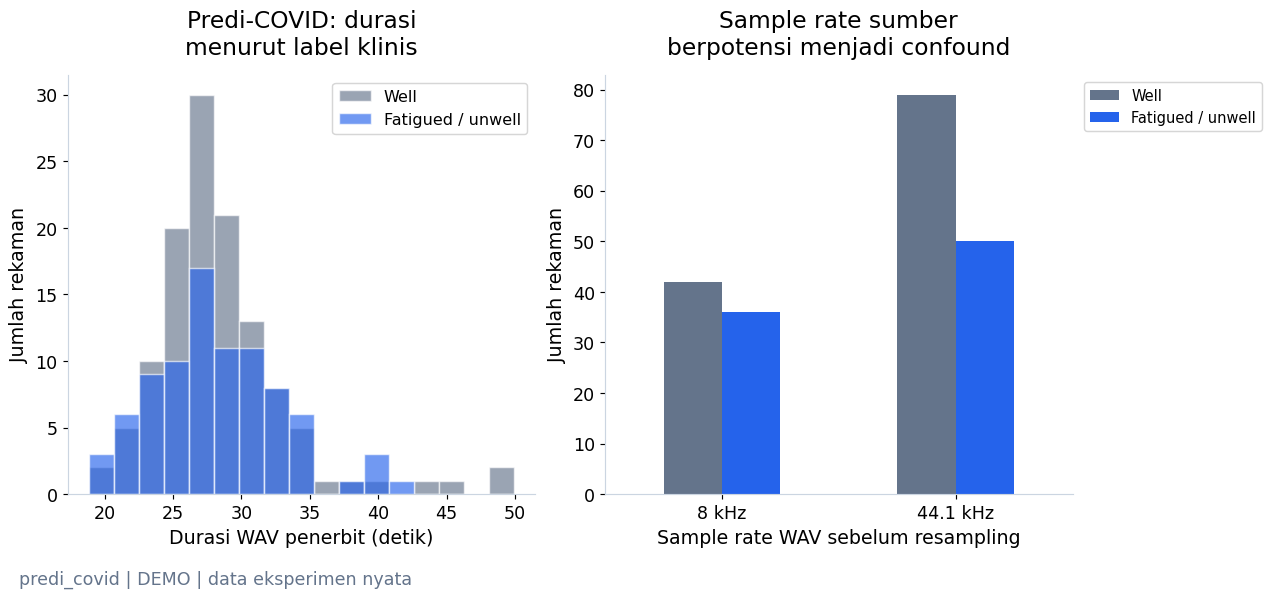

**Yang terlihat:** Durasi dan sample rate sumber bervariasi; seluruh WAV dianalisis pada 16 kHz melalui pipeline yang sama.

**Artinya:** Perbedaan perangkat atau protokol dapat menghasilkan pola suara yang berkorelasi dengan label.

**Perlu diingat:** Resampling 8 kHz ke 16 kHz tidak menciptakan informasi frekuensi baru dan tidak menghapus domain/device confound.

*Sumber: `20261022T133521652181Z_seed42_d98d66` · CACHED + contoh diproses langsung.*

Peserta dengan dua label berbeda pada subset: 14


In [24]:
if PREDI_AVAILABLE:
    fig,axes = plt.subplots(1,2,figsize=(12,5.2),layout='constrained')
    bins = np.linspace(predi_data.duration_seconds.min(),predi_data.duration_seconds.max(),18)
    for label,description,color in [(0,'Well',COLORS['secondary']),(1,'Fatigued / unwell',COLORS['audio'])]:
        subset = predi_data[predi_data.target_value.eq(label)]
        axes[0].hist(subset.duration_seconds,bins=bins,alpha=.65,color=color,label=description,edgecolor='white')
    axes[0].set(xlabel='Durasi WAV penerbit (detik)',ylabel='Jumlah rekaman',title='Predi-COVID: durasi\nmenurut label klinis')
    axes[0].legend(loc='upper right',fontsize=11)
    rates = pd.crosstab(predi_data.source_sample_rate,predi_data.target_value).rename(columns={0:'Well',1:'Fatigued / unwell'})
    rates.index = rates.index.map(lambda rate:f'{rate/1000:g} kHz')
    rates.plot.bar(ax=axes[1],rot=0,color=[COLORS['secondary'],COLORS['audio']])
    axes[1].set(xlabel='Sample rate WAV sebelum resampling',ylabel='Jumlah rekaman',title='Sample rate sumber\nberpotensi menjadi confound')
    axes[1].legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=10)
    predi_book.show(fig,'predi_audio_qc',
                    'Durasi dan sample rate sumber bervariasi; seluruh WAV dianalisis pada 16 kHz melalui pipeline yang sama.',
                    'Perbedaan perangkat atau protokol dapat menghasilkan pola suara yang berkorelasi dengan label.',
                    'Resampling 8 kHz ke 16 kHz tidak menciptakan informasi frekuensi baru dan tidak menghapus domain/device confound.')
    print('Peserta dengan dua label berbeda pada subset:',int(predi_data.groupby('subject_id').target_value.nunique().gt(1).sum()))

### 7.2 Tiga baseline, tanpa pencarian parameter pada test

**Dummy mayoritas** mengukur hasil jika model selalu menebak kelas paling banyak.
**Logistic Regression** memperkirakan hubungan linier fitur dengan kelas; **Linear SVM** mencari batas pemisah linier.
Keduanya memakai `C=1` dan bobot kelas seimbang yang ditetapkan sebelum evaluasi.
Imputasi median dan standardisasi berada di dalam pipeline, lalu di-fit **hanya** pada training.
Jenis kelamin, ID, tanggal, format perangkat, label dan nama file tidak menjadi input model: input hanya 114 fitur suara.

Outputnya berupa model tersimpan, prediksi validation/test, confusion matrix, Macro F1, balanced accuracy, serta recall per kelas.
Satu skor tinggi pun belum membuktikan bahwa pola yang dipelajari khusus fatigue; pola penyakit dan protokol dapat ikut terbaca.

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.363636,0.5,0.571429
logistic_c1,0.485714,0.486111,0.5
linear_svm_c1,0.525847,0.527778,0.547619


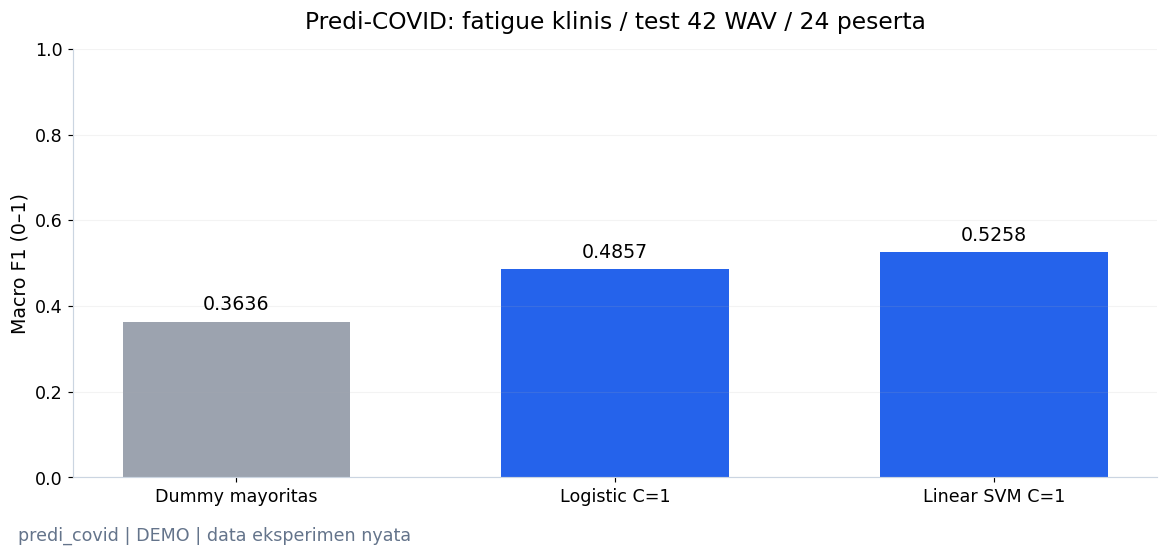

**Yang terlihat:** Ketiga model dievaluasi pada rekaman dan peserta test yang sama; semua skor berasal dari prediksi tersimpan.

**Artinya:** Macro F1 perlu dibaca bersama balanced accuracy: menebak kedua kelas dapat menaikkan F1 tanpa akurasi seimbang yang kuat.

**Perlu diingat:** Tidak ada tuning test; ukuran test kecil dan rekaman berulang membatasi kekuatan kesimpulan.

*Sumber: `20261022T133521652181Z_seed42_d98d66` · CACHED + contoh diproses langsung.*

**Interpretasi hasil yang dijalankan:** Logistic memiliki balanced accuracy 0.4861,
    dibandingkan Dummy 0.5000; Linear SVM = 0.5278.
    Kenaikan Macro F1 tidak cukup untuk menyatakan model kuat: balanced accuracy model linear masih dekat 0,5 pada 42 rekaman / 24 peserta test.
    Dengan dua kelas, 0,5 adalah acuan tebakan konstan pada balanced accuracy. Hasil ini belum menjadi bukti biomarker fatigue yang dapat digeneralisasi.
    Tidak dilakukan tuning untuk menaikkan angka test.

In [25]:
if PREDI_AVAILABLE:
    from sklearn.dummy import DummyClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import LinearSVC
    if RUN_MODE == 'FULL':
        predi_run.write('protocol.json',{'task':'reading_only','seed':42,'test_subject_fraction':.2,
                     'validation_fraction_of_remaining_subjects':.2,'feature_count':114,
                     'models':['dummy_most_frequent','logistic_C1_balanced','linear_svm_C1_balanced'],
                     'preprocessing':'median + StandardScaler fitted on train only','test_tuning':False,
                     'label_1':'fatigued OR unwell; same-day publisher label','selection_uses_model_scores':False})
        predi_scores,predi_prediction_parts = {},[]
        predi_estimators = {
            'dummy_majority':DummyClassifier(strategy='most_frequent'),
            'logistic_c1':LogisticRegression(C=1,class_weight='balanced',max_iter=2000,random_state=config['seed']),
            'linear_svm_c1':LinearSVC(C=1,class_weight='balanced',dual='auto',max_iter=20000,random_state=config['seed'])}
        training = predi_data[predi_data.split.eq('train')]
        for name,estimator in predi_estimators.items():
            model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),estimator)
            model.fit(training[audio_columns],training.target_value)
            save_model(predi_run,name,model,audio_columns,predi_data[~predi_data.split.eq('train')])
            predi_scores[name] = {'reload_verified':True,'feature_count':len(audio_columns)}
            for partition in ['validation','test']:
                holdout = predi_data[predi_data.split.eq(partition)]
                predicted = model.predict(holdout[audio_columns])
                predi_scores[name][partition] = classification_metrics(holdout.target_value,predicted,[0,1])
                predi_prediction_parts.append(prediction_table(holdout,predicted,name))
        predi_predictions = pd.concat(predi_prediction_parts,ignore_index=True)
        predi_predictions.to_csv(predi_run.file('predictions/holdout_predictions.csv'),index=False)
        predi_metrics = metrics_base(predi_run,predi_scores,predi_sizes,{'0':'well','1':'fatigued OR unwell'},'dummy_majority')
        predi_metrics['scope'] = 'clinical_fatigue_subset_benchmark; not_occupational_ATC_fatigue'
    else:
        predi_predictions = pd.read_csv(predi_run.path/'predictions/holdout_predictions.csv',dtype={'subject_id':str})
        for name in predi_metrics['models']:
            verify_cached_predictions(predi_run,predi_data[predi_data.split.eq('test')],predi_predictions,name)
    predi_test_scores = {name:value['test'] for name,value in predi_metrics['models'].items()}
    display(pd.DataFrame(predi_test_scores).T[['macro_f1','balanced_accuracy','accuracy']])
    fig = model_bars(predi_test_scores,'macro_f1',
                     f'Predi-COVID: fatigue klinis / test {predi_sizes["test"]} WAV / {predi_data[predi_data.split.eq("test")].subject_id.nunique()} peserta',
                     'Macro F1 (0–1)',COLORS['audio'])
    fig.axes[0].set_xticks(fig.axes[0].get_xticks(),labels=['Dummy mayoritas','Logistic C=1','Linear SVM C=1'])
    fig.axes[0].set_ylim(0,1)
    predi_book.show(fig,'predi_model_comparison',
                    'Ketiga model dievaluasi pada rekaman dan peserta test yang sama; semua skor berasal dari prediksi tersimpan.',
                    'Macro F1 perlu dibaca bersama balanced accuracy: menebak kedua kelas dapat menaikkan F1 tanpa akurasi seimbang yang kuat.',
                    'Tidak ada tuning test; ukuran test kecil dan rekaman berulang membatasi kekuatan kesimpulan.')
    display(Markdown(f"""**Interpretasi hasil yang dijalankan:** Logistic memiliki balanced accuracy {predi_test_scores['logistic_c1']['balanced_accuracy']:.4f},
    dibandingkan Dummy {predi_test_scores['dummy_majority']['balanced_accuracy']:.4f}; Linear SVM = {predi_test_scores['linear_svm_c1']['balanced_accuracy']:.4f}.
    Kenaikan Macro F1 tidak cukup untuk menyatakan model kuat: balanced accuracy model linear masih dekat 0,5 pada {predi_sizes['test']} rekaman / 24 peserta test.
    Dengan dua kelas, 0,5 adalah acuan tebakan konstan pada balanced accuracy. Hasil ini belum menjadi bukti biomarker fatigue yang dapat digeneralisasi.
    Tidak dilakukan tuning untuk menaikkan angka test."""))

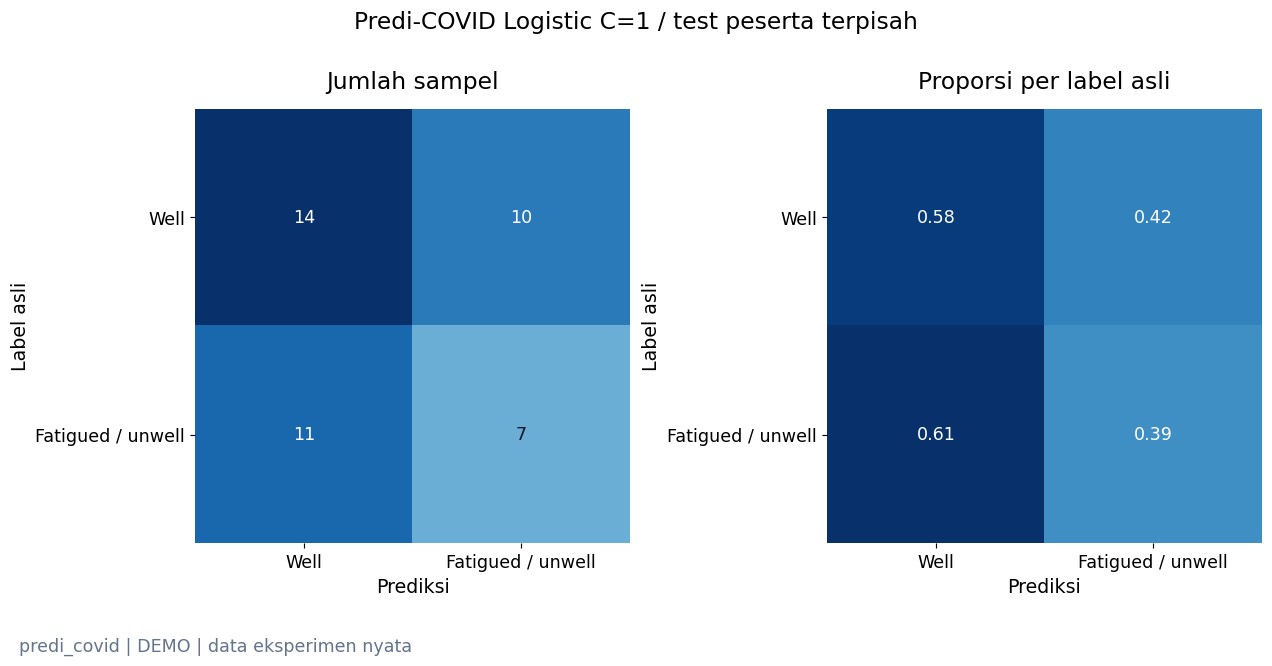

**Yang terlihat:** Confusion matrix berjumlah 42 rekaman; sisi kanan dinormalisasi berdasarkan kelas asli.

**Artinya:** Recall kelas 1 menunjukkan proporsi laporan fatigued/unwell yang ditemukan, sementara kelas 0 memeriksa false alarms.

**Perlu diingat:** Logistic dipilih sebagai baseline interpretabel sebelum melihat skor, bukan sebagai pemenang test.

*Sumber: `20261022T133521652181Z_seed42_d98d66` · CACHED + contoh diproses langsung.*

,precision,recall,f1-score,support
Well,0.560000,0.583333,0.571429,24.0
Fatigued / unwell,0.411765,0.388889,0.400000,18.0


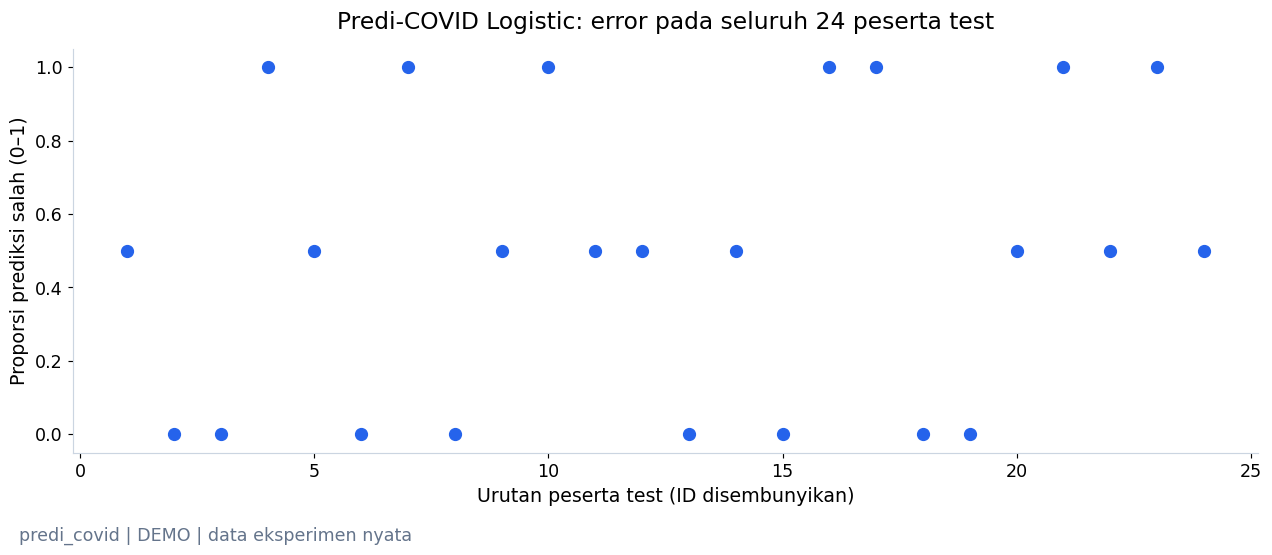

**Yang terlihat:** 21 dari 42 rekaman test salah; semua peserta ditampilkan tanpa seleksi hasil terbaik.

**Artinya:** Error dapat terkonsentrasi pada orang tertentu; ringkasan klip saja menyembunyikan variasi tersebut.

**Perlu diingat:** Hanya satu atau dua rekaman per peserta; error 0 atau 1 bukan estimasi presisi tentang kemampuan individual.

*Sumber: `20261022T133521652181Z_seed42_d98d66` · CACHED + contoh diproses langsung.*

Rerata error per peserta: 0.4792


Rekaman  Peserta  \
source_format sex_metadata source_sample_rate                     
3gp           M            8000                     17        9   
              W            8000                      8        5   
m4a           M            44100                    10        6   
              W            44100                     7        4   

                                               Proporsi_error  
source_format sex_metadata source_sample_rate                  
3gp           M            8000                         0.529  
              W            8000                         0.500  
m4a           M            44100                        0.500  
              W            44100                        0.429

Kelompok perangkat/demografi kecil dan tidak diacak. Perbedaan error ini bersifat deskriptif, tidak mengidentifikasi sebab atau membuktikan fairness.

In [26]:
if PREDI_AVAILABLE:
    predi_result = predi_test_scores['logistic_c1']
    fig = confusion_pair(predi_result,['Well','Fatigued / unwell'],'Predi-COVID Logistic C=1 / test peserta terpisah')
    predi_book.show(fig,'predi_confusion',
                    f'Confusion matrix berjumlah {predi_sizes["test"]} rekaman; sisi kanan dinormalisasi berdasarkan kelas asli.',
                    'Recall kelas 1 menunjukkan proporsi laporan fatigued/unwell yang ditemukan, sementara kelas 0 memeriksa false alarms.',
                    'Logistic dipilih sebagai baseline interpretabel sebelum melihat skor, bukan sebagai pemenang test.')
    display(pd.DataFrame({label:predi_result['classification_report'][str(value)]
                          for value,label in [(0,'Well'),(1,'Fatigued / unwell')]}).T[['precision','recall','f1-score','support']])
    predi_errors = predi_predictions[predi_predictions.model.eq('logistic_c1') & predi_predictions.split.eq('test')].copy()
    predi_errors['error'] = predi_errors.truth.ne(predi_errors.prediction)
    subject_errors = predi_errors.groupby('subject_id').agg(error_rate=('error','mean'),recordings=('sample_id','size')).sort_index()
    fig,ax = plt.subplots(figsize=(12,4.8),layout='constrained')
    ax.scatter(np.arange(1,len(subject_errors)+1),subject_errors.error_rate,color=COLORS['audio'],s=65)
    ax.set(xlabel='Urutan peserta test (ID disembunyikan)',ylabel='Proporsi prediksi salah (0–1)',ylim=(-.05,1.05),
           title=f'Predi-COVID Logistic: error pada seluruh {len(subject_errors)} peserta test')
    predi_book.show(fig,'predi_error_per_subject',
                    f'{int(predi_errors.error.sum())} dari {len(predi_errors)} rekaman test salah; semua peserta ditampilkan tanpa seleksi hasil terbaik.',
                    'Error dapat terkonsentrasi pada orang tertentu; ringkasan klip saja menyembunyikan variasi tersebut.',
                    'Hanya satu atau dua rekaman per peserta; error 0 atau 1 bukan estimasi presisi tentang kemampuan individual.')
    print('Rerata error per peserta:',round(subject_errors.error_rate.mean(),4))
    stratified_errors = predi_errors.merge(predi_data[['sample_id','source_format','sex_metadata','source_sample_rate']],on='sample_id',validate='one_to_one')
    display(stratified_errors.groupby(['source_format','sex_metadata','source_sample_rate']).agg(
        Rekaman=('sample_id','size'),Peserta=('subject_id','nunique'),Proporsi_error=('error','mean')).round(3))
    display(Markdown('Kelompok perangkat/demografi kecil dan tidak diacak. Perbedaan error ini bersifat deskriptif, tidak mengidentifikasi sebab atau membuktikan fairness.'))
    predi_book.finish()
    if RUN_MODE == 'FULL':
        predi_run.complete(predi_metrics,{'evaluation_rows':len(predi_data),'source_rows':len(predi_manifest),
                           'feature_missing_fraction':float(predi_data[audio_columns].isna().mean().mean()),
                           'quality_counts':predi_data.quality.value_counts().to_dict(),
                           'subject_overlap':0,'checksum_overlap':0,'no_model_based_exclusions':True},warning_records)
warning_context.__exit__(None,None,None)

### 7.3 Perbandingan yang masuk akal dan batas interpretasi

ATCOSIM menjawab apakah suara domain ATC dapat diolah, sedangkan Predi-COVID menguji hubungan akustik dengan
**label klinis yang tercatat**. Keduanya tidak berbagi target, populasi, bahasa, perangkat atau protokol yang sama.
Karena itu skor Predi-COVID tidak dapat dipindahkan menjadi estimasi performa pada radio ATC.

Ekstraksi 114 fitur juga merangkum satu ujaran menjadi statistik: urutan naik-turunnya suara hilang dan
perubahan fatigue di dalam ujaran tidak dilabeli. Studi lanjutan membutuhkan rekaman operator dengan target fatigue terdefinisi,
label waktu yang sesuai, izin peserta, serta test subjek/sesi independen. Hasil tidak diklaim sebagai diagnosis atau alat operasional.

**Kesimpulan:** data suara ATC asli berhasil masuk ke tabel fitur, tetapi tidak menghasilkan skor fatigue. Untuk mengulang seluruh subset, jalankan `ATC_NOTEBOOK_MODE=FULL .venv/bin/python scripts/10_execute_notebook_v3.py --mode FULL --notebook 01_audio_analysis.ipynb`. Mode DEMO adalah pilihan presentasi; petunjuk lengkap ada di [README v3](README.md).

Predi-COVID menambah supervised benchmark label fatigue/unwell klinis, dengan batas domain dan label yang dijelaskan di Bagian 7. Tidak ada estimasi performa fatigue ATC.